In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (1).png
/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (1)_mask.png
/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (10).png
/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (10)_mask.png
/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (100).png
/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (100)_mask.png
/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (100)_mask_1.png
/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (101).png
/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/

In [1]:
import os

os.makedirs("/kaggle/working/src", exist_ok=True)
os.makedirs("/kaggle/working/results", exist_ok=True)

print("Project folders created!")

Project folders created!


In [3]:

%%writefile /kaggle/working/src/dataset.py

from pathlib import Path
import hashlib

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from sklearn.model_selection import train_test_split


CLASSES = ["normal", "benign", "malignant"]


# Image transformations
train_tf = T.Compose([
    T.Grayscale(num_output_channels=3),
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(10),
    T.ToTensor(),
    T.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

eval_tf = T.Compose([
    T.Grayscale(num_output_channels=3),
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])


# Collect images and labels
def collect_samples(root):
    root = Path(root)
    samples = []

    for class_name in CLASSES:
        class_folder = root / class_name

        if not class_folder.exists():
            raise FileNotFoundError(class_folder)

        for path in sorted(class_folder.glob("*.png")):
            if "_mask" not in path.name:
                label = CLASSES.index(class_name)
                samples.append((path, label))

    return samples


# Calculate SHA-256 hash
def get_file_hash(path):
    sha256 = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


# Remove exact duplicates
def remove_duplicates(samples):
    seen = {}
    unique_samples = []

    for path, label in samples:
        image_hash = get_file_hash(path)

        if image_hash in seen:
            previous_path, previous_label = seen[image_hash]

            if previous_label != label:
                raise ValueError(
                    f"Identical image has conflicting labels: "
                    f"{previous_path} and {path}"
                )

            print("Duplicate removed:", path.name)
            continue

        seen[image_hash] = (path, label)
        unique_samples.append((path, label))

    print("Original images:", len(samples))
    print("Unique images:", len(unique_samples))
    print("Duplicates removed:", len(samples) - len(unique_samples))

    return unique_samples


# Split dataset
def split_dataset(samples, seed=42):
    labels = [label for _, label in samples]

    train_samples, temp_samples = train_test_split(
        samples,
        test_size=0.30,
        stratify=labels,
        random_state=seed
    )

    val_samples, test_samples = train_test_split(
        temp_samples,
        test_size=0.50,
        stratify=[label for _, label in temp_samples],
        random_state=seed
    )

    return train_samples, val_samples, test_samples


# Custom Dataset
class BUSIDataset(Dataset):

    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, label = self.samples[index]

        image = Image.open(image_path).convert("L")

        if self.transform:
            image = self.transform(image)

        return image, label


# Create DataLoaders
def create_dataloaders(root, batch_size=16, seed=42):

    samples = collect_samples(root)
    samples = remove_duplicates(samples)

    train_samples, val_samples, test_samples = split_dataset(
        samples, seed=seed
    )

    train_dataset = BUSIDataset(train_samples, train_tf)
    val_dataset = BUSIDataset(val_samples, eval_tf)
    test_dataset = BUSIDataset(test_samples, eval_tf)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    return train_loader, val_loader, test_loader


Writing /kaggle/working/src/dataset.py


In [4]:
import os

print(os.path.exists("/kaggle/working/src/dataset.py"))

True


In [5]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    if "normal" in dirs and "benign" in dirs and "malignant" in dirs:
        print("Your DATA_ROOT is:", root)

Your DATA_ROOT is: /kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT


In [7]:
import os

DATA_ROOT = "/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT"

print("Directory exists:", os.path.isdir(DATA_ROOT))
print("Folders:", os.listdir(DATA_ROOT))

Directory exists: True
Folders: ['benign', 'malignant', 'normal']


In [8]:
import sys
sys.path.append("/kaggle/working")

from src.dataset import create_dataloaders

train_loader, val_loader, test_loader = create_dataloaders(
    DATA_ROOT,
    batch_size=16
)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels)

ValueError: Identical image has conflicting labels: /kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (433).png and /kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/malignant/malignant (145).png

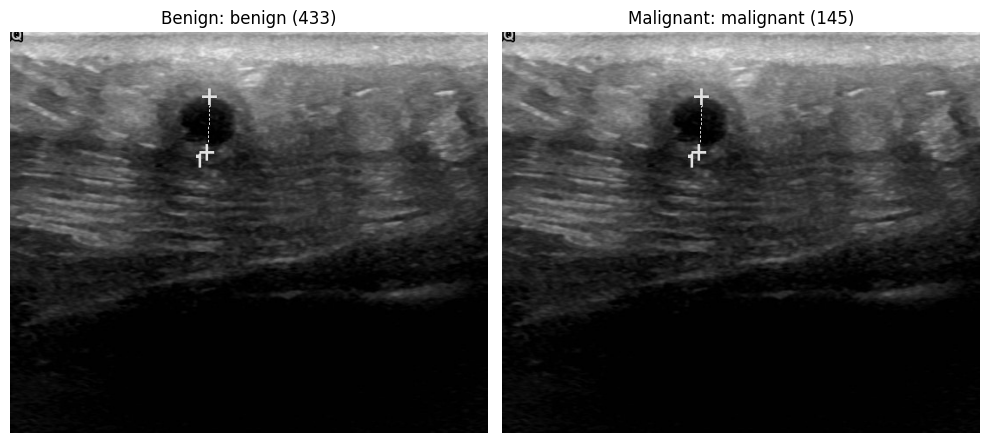

In [9]:
from PIL import Image
import matplotlib.pyplot as plt

img1_path = DATA_ROOT + "/benign/benign (433).png"
img2_path = DATA_ROOT + "/malignant/malignant (145).png"

img1 = Image.open(img1_path)
img2 = Image.open(img2_path)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(img1, cmap="gray")
axes[0].set_title("Benign: benign (433)")
axes[0].axis("off")

axes[1].imshow(img2, cmap="gray")
axes[1].set_title("Malignant: malignant (145)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [10]:
from pathlib import Path
import hashlib

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

print("Benign hash:", sha256(img1_path))
print("Malignant hash:", sha256(img2_path))
print("Identical:", sha256(img1_path) == sha256(img2_path))

Benign hash: 058e7538fa53b2bd8b87500ff47721c84ec442dc964d9de21bb271a8651138a8
Malignant hash: 058e7538fa53b2bd8b87500ff47721c84ec442dc964d9de21bb271a8651138a8
Identical: True


In [27]:

%%writefile /kaggle/working/src/dataset.py

from pathlib import Path
import hashlib

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from PIL import Image


# Class names and labels
CLASSES = ["normal", "benign", "malignant"]


# Transformations for training images
train_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Transformations for validation and test images
eval_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Collect original images and their labels
def collect_samples(root):

    root = Path(root)
    samples = []

    for class_name in CLASSES:

        class_folder = root / class_name

        images = [
            path for path in class_folder.glob("*.png")
            if "_mask" not in path.name.lower()
        ]

        label = CLASSES.index(class_name)

        for path in images:
            samples.append((path, label))

    return samples


# Calculate SHA-256 hash of an image
def get_file_hash(path):

    sha256 = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(8192), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


# Remove exact duplicates safely
def remove_duplicates(samples):

    hash_groups = {}

    for path, label in samples:

        image_hash = get_file_hash(path)

        if image_hash not in hash_groups:
            hash_groups[image_hash] = []

        hash_groups[image_hash].append((path, label))

    unique_samples = []
    conflicting_groups = 0
    conflicting_images = 0
    duplicate_count = 0

    for image_hash, group in hash_groups.items():

        labels = {label for _, label in group}

        # Exclude all copies if identical images have conflicting labels
        if len(labels) > 1:

            conflicting_groups += 1
            conflicting_images += len(group)

            print("\nConflicting group excluded:")

            for path, label in group:
                print(CLASSES[label], ":", path.name)

            continue

        # Keep one copy for same-label duplicates
        unique_samples.append(group[0])
        duplicate_count += len(group) - 1

    print("\nDuplicate detection summary")
    print("---------------------------")
    print("Original images:", len(samples))
    print("Unique usable images:", len(unique_samples))
    print("Same-label duplicates removed:", duplicate_count)
    print("Conflicting groups excluded:", conflicting_groups)
    print("Images excluded due to conflicting labels:", conflicting_images)

    return unique_samples


# Split data into training, validation, and testing
def split_dataset(samples, seed=42):

    labels = [label for _, label in samples]

    train_samples, temp_samples = train_test_split(
        samples,
        test_size=0.30,
        random_state=seed,
        stratify=labels
    )

    temp_labels = [label for _, label in temp_samples]

    val_samples, test_samples = train_test_split(
        temp_samples,
        test_size=0.50,
        random_state=seed,
        stratify=temp_labels
    )

    return train_samples, val_samples, test_samples


# PyTorch Dataset class
class BUSIDataset(Dataset):

    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):

        image_path, label = self.samples[index]

        image = Image.open(image_path).convert("L")

        if self.transform:
            image = self.transform(image)

        return image, label


# Create DataLoaders
def create_dataloaders(root, batch_size=16, seed=42):

    samples = collect_samples(root)

    print("Images collected:", len(samples))

    samples = remove_duplicates(samples)

    train_samples, val_samples, test_samples = split_dataset(
        samples,
        seed=seed
    )

    train_dataset = BUSIDataset(train_samples, train_tf)
    val_dataset = BUSIDataset(val_samples, eval_tf)
    test_dataset = BUSIDataset(test_samples, eval_tf)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    print("\nDataset split summary")
    print("---------------------")
    print("Training:", len(train_dataset))
    print("Validation:", len(val_dataset))
    print("Testing:", len(test_dataset))

    return train_loader, val_loader, test_loader


Overwriting /kaggle/working/src/dataset.py


In [29]:
from pathlib import Path

file_path = Path("/kaggle/working/src/dataset.py")

print("File exists:", file_path.exists())
print("File size:", file_path.stat().st_size, "bytes")
print(file_path.read_text()[:500])

File exists: True
File size: 5199 bytes

from pathlib import Path
import hashlib

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from PIL import Image


# Class names and labels
CLASSES = ["normal", "benign", "malignant"]


# Transformations for training images
train_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.


# Import and create DataLoaders

In [30]:
import sys
import importlib

sys.path.append("/kaggle/working")

import src.dataset as dataset
importlib.reload(dataset)

train_loader, val_loader, test_loader = dataset.create_dataloaders(
    DATA_ROOT,
    batch_size=16,
    seed=42
)

Images collected: 780

Conflicting group excluded:
benign : benign (433).png
malignant : malignant (145).png

Duplicate detection summary
---------------------------
Original images: 780
Unique usable images: 778
Same-label duplicates removed: 0
Conflicting groups excluded: 1
Images excluded due to conflicting labels: 2

Dataset split summary
---------------------
Training: 544
Validation: 117
Testing: 117


# Ckeck class distribution

In [31]:
from collections import Counter

def show_class_distribution(loader, split_name):

    labels = [
        label
        for _, label in loader.dataset.samples
    ]

    counts = Counter(labels)

    print(f"\n{split_name} distribution")
    print("----------------------")

    for index, class_name in enumerate(dataset.CLASSES):
        print(f"{class_name}: {counts[index]}")


show_class_distribution(train_loader, "Training")
show_class_distribution(val_loader, "Validation")
show_class_distribution(test_loader, "Testing")


Training distribution
----------------------
normal: 93
benign: 305
malignant: 146

Validation distribution
----------------------
normal: 20
benign: 65
malignant: 32

Testing distribution
----------------------
normal: 20
benign: 66
malignant: 31


# Check tensor shapes

In [32]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)
print("Minimum pixel value:", images.min().item())
print("Maximum pixel value:", images.max().item())

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Image data type: torch.float32
Label data type: torch.int64
Minimum pixel value: -2.1179039478302
Maximum pixel value: 2.640000104904175


# Visualize training batch

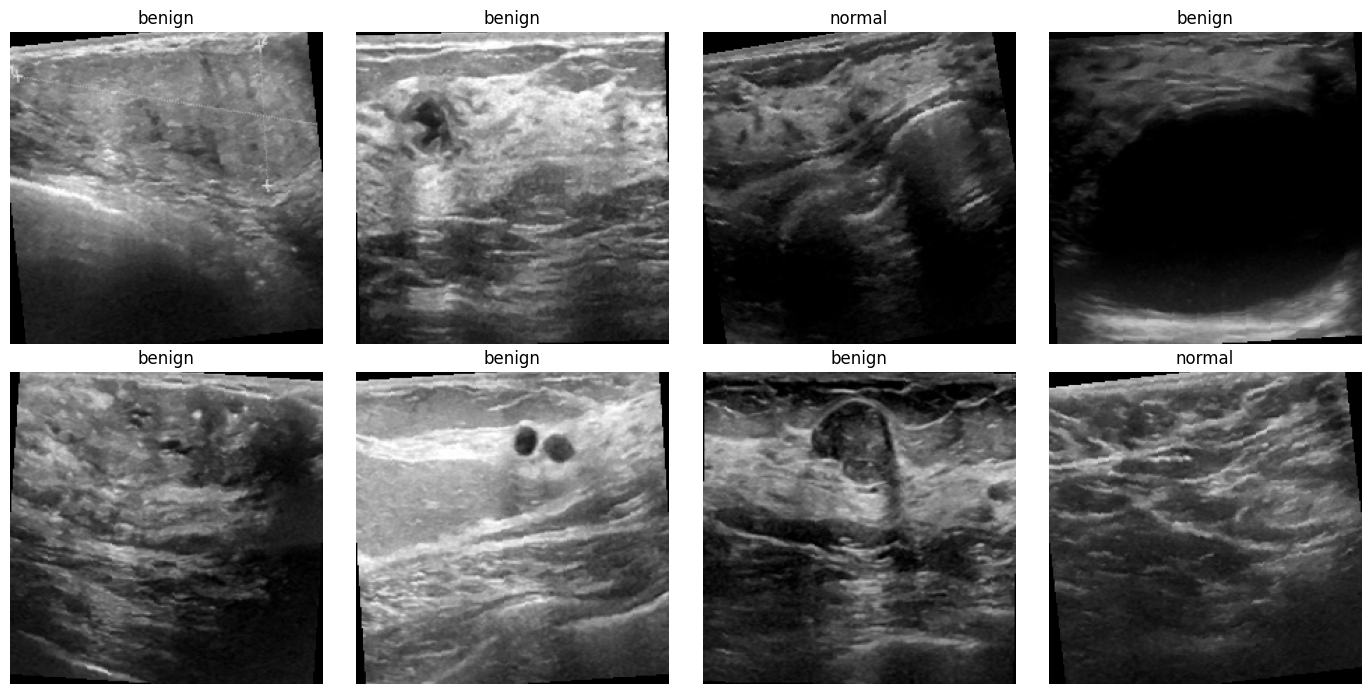

In [33]:
import matplotlib.pyplot as plt
import numpy as np

images, labels = next(iter(train_loader))

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flat):

    image = images[i].permute(1, 2, 0).numpy()

    # Reverse ImageNet normalization
    image = image * std + mean
    image = np.clip(image, 0, 1)

    ax.imshow(image)
    ax.set_title(dataset.CLASSES[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()